<a href="https://colab.research.google.com/github/devansh98185/CSET343/blob/main/Lab_Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install nltk wordcloud gensim pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 41.2 MB/s eta 0:00:00


In [ ]:
import os
import re
import glob
import json
import warnings
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from collections import Counter
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from gensim import corpora
from gensim.models import LdaModel

warnings.filterwarnings("ignore")

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("Libraries imported successfully.")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported successfully.


In [ ]:
repo_url = "https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing.git"
repo_dir = "/content/health_headlines_dataset"

if not os.path.exists(repo_dir):
    result = subprocess.run(
        ["git", "clone", "--depth", "1", repo_url, repo_dir],
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Dataset download failed.")

files = (
    glob.glob(repo_dir + "/**/*.csv", recursive=True)
    + glob.glob(repo_dir + "/**/*.json", recursive=True)
)

print("Dataset files found:")
for file in files:
    print(file)

if not files:
    raise FileNotFoundError(
        "No CSV or JSON files found. Check the repository contents."
    )

data_file = files[0]

if data_file.endswith(".csv"):
    df = pd.read_csv(data_file)
else:
    try:
        df = pd.read_json(data_file)
    except ValueError:
        df = pd.read_json(data_file, lines=True)

print("\nDataset loaded:", data_file)
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

Dataset files found:
/content/health_headlines_dataset/Clinical_Trials_Journals_Headlines.csv
/content/health_headlines_dataset/Patient_Safety_Journals_Headlines.csv
/content/health_headlines_dataset/Pain_management_Features_Headlines.csv
/content/health_headlines_dataset/Adverse_Drug_Reaction_News_Headlines.csv
/content/health_headlines_dataset/Clinical_Trials_Perspective_Headlines.csv
/content/health_headlines_dataset/Pain_Management_Journals_Headlines.csv
/content/health_headlines_dataset/Peadiatric_Immunization_News_Headlines.csv
/content/health_headlines_dataset/Substance_Abuse_and_Addiction_Perspective_Headlines.csv
/content/health_headlines_dataset/Peadiatric_Immunization_Features_Headlines.csv
/content/health_headlines_dataset/Clinical_Trials_Related_Headlines.csv
/content/health_headlines_dataset/Adverse_Drug_Events_Related_Headlines.csv
/content/health_headlines_dataset/Health_Related_Headlines_Dataset.csv
/content/health_headlines_dataset/Antibiotic_Resistance_Related_Headli

,Date,Source,Headlines,Teaser
0,July 2002,Neurosurgical Focus,Outcome Measures for Clinical Trials in Neurot...,More than 40 years have passed since the first...
1,June 2002,Southern Medical Journal,Selected Ongoing Clinical Trials,The following trials are designed to help phys...
2,July 2002,Medscape General Medicine,Medscape Psychopharmacology Today,Development process for drugs
3,May 2002,Southern Medical Journal,Selected Ongoing Clinical Trials,The following trials are designed to help phys...
4,June 2001,Abstracts in Hematology & OncologyTM,Urothelial Cancer: A Phase II Trial,A study evaluates efficacy and toxicity in pre...


In [ ]:
text_columns = [
    column for column in df.columns
    if any(
        term in column.lower()
        for term in ["headline", "title", "teaser", "text", "description"]
    )
]

if not text_columns:
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()

if not text_columns:
    raise ValueError("No text columns were found in the dataset.")

print("Selected text columns:", text_columns)

df["raw_text"] = (
    df[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

df = df[df["raw_text"].ne("")].copy()
df = df.drop_duplicates(subset=["raw_text"]).reset_index(drop=True)

print("Records available for analysis:", len(df))
display(df[["raw_text"]].head())

Selected text columns: ['Headlines', 'Teaser']
Records available for analysis: 4005


,raw_text
0,Outcome Measures for Clinical Trials in Neurot...
1,Selected Ongoing Clinical Trials The following...
2,Medscape Psychopharmacology Today Development ...
3,Selected Ongoing Clinical Trials The following...
4,Urothelial Cancer: A Phase II Trial A study ev...


In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)

    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 2
    ]

    return cleaned_tokens

df["clean_tokens"] = df["raw_text"].apply(clean_text)
df["clean_text"] = df["clean_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

df = df[df["clean_text"].str.strip().ne("")].reset_index(drop=True)

print("Original and cleaned text samples:\n")

for index, row in df.head(5).iterrows():
    print("Original:", row["raw_text"][:300])
    print("Cleaned: ", row["clean_text"][:300])
    print("-" * 70)

print("Final number of text records:", len(df))

Original and cleaned text samples:

Original: Outcome Measures for Clinical Trials in Neurotrauma More than 40 years have passed since the first therapeutic trials were designed to test the ability of medications to improve outcome after severe TBI.
Cleaned:  outcome measure clinical trial neurotrauma year passed since first therapeutic trial designed test ability medication improve outcome severe tbi
----------------------------------------------------------------------
Original: Selected Ongoing Clinical Trials The following trials are designed to help physicians treat osteoporosis.
Cleaned:  selected ongoing clinical trial following trial designed help physician treat osteoporosis
----------------------------------------------------------------------
Original: Medscape Psychopharmacology Today Development process for drugs
Cleaned:  medscape psychopharmacology today development process drug
----------------------------------------------------------------------
Original: Selected Ong

Top 20 most frequent words:


,Word,Frequency
0,patient,1538
1,treatment,985
2,therapy,683
3,cancer,657
4,disease,618
5,study,572
6,risk,566
7,new,561
8,clinical,505
9,drug,437


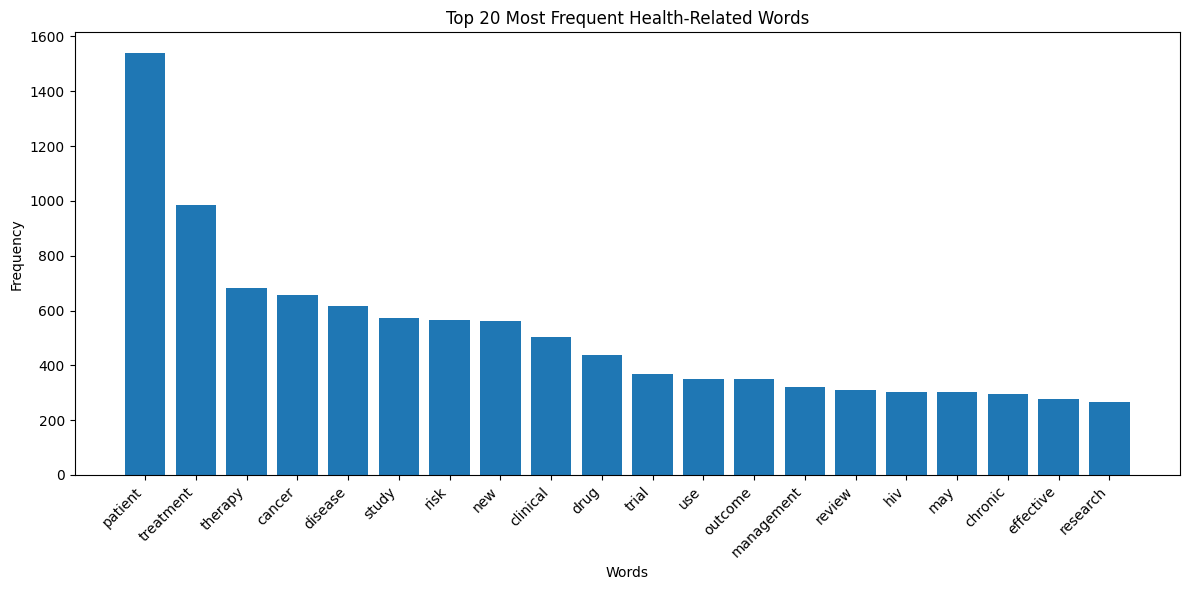

In [ ]:
all_words = [
    word
    for tokens in df["clean_tokens"]
    for word in tokens
]

word_counts = Counter(all_words)
frequency_df = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

print("Top 20 most frequent words:")
display(frequency_df)

plt.figure(figsize=(12, 6))
plt.bar(
    frequency_df["Word"],
    frequency_df["Frequency"]
)
plt.title("Top 20 Most Frequent Health-Related Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

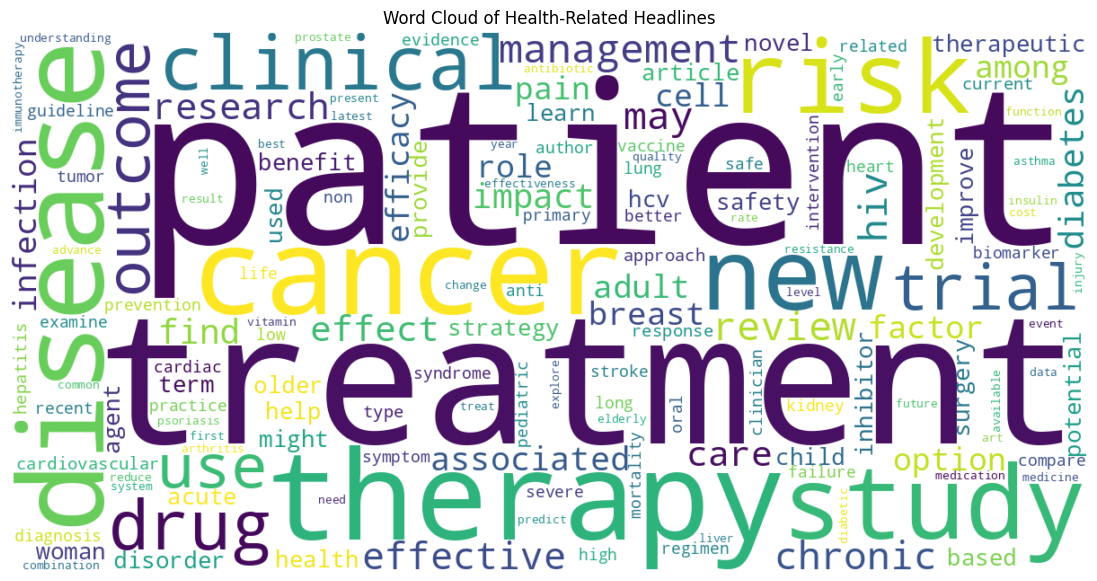

In [ ]:
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    collocations=False
).generate(" ".join(all_words))

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Health-Related Headlines")
plt.show()

In [ ]:
dictionary = corpora.Dictionary(df["clean_tokens"])

dictionary.filter_extremes(
    no_below=2,
    no_above=0.90
)

corpus = [
    dictionary.doc2bow(tokens)
    for tokens in df["clean_tokens"]
]

if len(dictionary) == 0 or not any(corpus):
    raise ValueError(
        "The vocabulary is empty. Review preprocessing or relax filtering."
    )

num_topics = min(5, len(dictionary))

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=num_topics,
    random_state=42,
    passes=10,
    iterations=100,
    alpha="auto",
    per_word_topics=True
)

print("LDA model trained successfully.")
print("Number of topics:", num_topics)
print("Vocabulary size:", len(dictionary))

LDA model trained successfully.
Number of topics: 5
Vocabulary size: 3983


In [ ]:
for topic_id in range(num_topics):
    words = lda_model.show_topic(topic_id, topn=5)

    print(f"\nTopic {topic_id + 1}:")
    print(", ".join(
        f"{word} ({weight:.3f})"
        for word, weight in words
    ))


Topic 1:
cardiovascular (0.072), kidney (0.071), transplant (0.067), disease (0.067), artery (0.067)

Topic 2:
patient (0.082), stroke (0.059), peripheral (0.055), disease (0.046), risk (0.032)

Topic 3:
treatment (0.071), use (0.053), disorder (0.036), advanced (0.035), recent (0.035)

Topic 4:
cancer (0.025), treatment (0.017), new (0.015), drug (0.013), therapy (0.012)

Topic 5:
patient (0.023), treatment (0.016), study (0.012), therapy (0.012), clinical (0.012)


In [ ]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

lda_visualization = gensimvis.prepare(
    lda_model,
    corpus,
    dictionary,
    sort_topics=False
)

pyLDAvis.display(lda_visualization)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
output_dir = "/content/lab8_outputs"
os.makedirs(output_dir, exist_ok=True)

df[["raw_text", "clean_text"]].to_csv(
    f"{output_dir}/cleaned_health_headlines.csv",
    index=False
)

frequency_df.to_csv(
    f"{output_dir}/word_frequency.csv",
    index=False
)

plt.figure(figsize=(12, 6))
plt.bar(frequency_df["Word"], frequency_df["Frequency"])
plt.title("Top 20 Health-Related Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    f"{output_dir}/top_20_words.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

wordcloud.to_file(f"{output_dir}/word_cloud.png")

pyLDAvis.save_html(
    lda_visualization,
    f"{output_dir}/lda_visualization.html"
)

print("All outputs saved in:", output_dir)
print(os.listdir(output_dir))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

All outputs saved in: /content/lab8_outputs
['word_cloud.png', 'lda_visualization.html', 'cleaned_health_headlines.csv', 'top_20_words.png', 'word_frequency.csv']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
'''import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/Lab_Assignment_8_Outputs",
    "zip",
    output_dir
)

files.download(zip_path)'''

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

'import shutil\nfrom google.colab import files\n\nzip_path = shutil.make_archive(\n    "/content/Lab_Assignment_8_Outputs",\n    "zip",\n    output_dir\n)\n\nfiles.download(zip_path)'

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag